# Exercise 1 (10 points)

In this exercise, we will practice how to properly format code. You are given a simple but poorly formatted Python code snippet that performs some common data science tasks (loading data, cleaning, and basic analysis). Your task is to refactor the code to improve readability, organization, and adhere to Python's PEP8 formatting guidelines.

```
import pandas as pd 
import numpy as np

data=pd.read_csv('credit_risk_dataset.csv')
# drop rows with missing values
data=data.dropna()

cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
def converting_datatypes(df, cat_cols, df_train=False):
    
    for col in cat_cols:
        df[col] = df[col].astype('category')
    
    df['person_age'] = df['person_age'].astype('int32')
    df['cb_person_cred_hist_length'] = df['cb_person_cred_hist_length'].astype('int32') 
    
    if df_train==True:

        df['loan_status'] = df['loan_status'].astype('int8')
        
    return df
        
data = converting_datatypes(data, cat_cols, df_train=True)

X=data.drop('loan_status',axis=1)
y=data['loan_status']

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

from sklearn.ensemble import HistGradientBoostingClassifier
hg=HistGradientBoostingClassifier(n_estimators=100, categorical_features='from_dtype')
hg.fit(X_train,y_train)
print('Train accuracy:',hg.score(X_train,y_train))
print('Test accuracy:',hg.score(X_test,y_test))
```

In [2]:
import pandas as pd 
import numpy as np

data=pd.read_csv('credit_risk_dataset.csv')
# drop rows with missing values
data=data.dropna()

cat_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
def converting_datatypes(df, cat_cols, df_train=False):
    
    for col in cat_cols:
        df[col] = df[col].astype('category')
    
    df['person_age'] = df['person_age'].astype('int32')
    df['cb_person_cred_hist_length'] = df['cb_person_cred_hist_length'].astype('int32') 
    
    if df_train==True:

        df['loan_status'] = df['loan_status'].astype('int8')
        
    return df
        
data = converting_datatypes(data, cat_cols, df_train=True)

X=data.drop('loan_status',axis=1)
y=data['loan_status']

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

from sklearn.ensemble import HistGradientBoostingClassifier
hg=HistGradientBoostingClassifier(max_iter=100, categorical_features='from_dtype')
hg.fit(X_train,y_train)
print('Train accuracy:',hg.score(X_train,y_train))
print('Test accuracy:',hg.score(X_test,y_test))


Train accuracy: 0.9444278160231467
Test accuracy: 0.9327281191806331


In [6]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier


# Load data and remove missing values
data = pd.read_csv("credit_risk_dataset.csv")
data = data.dropna()


# Convert column data types
cat_cols = [
    "person_home_ownership",
    "loan_intent",
    "loan_grade",
    "cb_person_default_on_file"
]


def converting_datatypes(df, cat_cols, df_train=False):
    for col in cat_cols:
        df[col] = df[col].astype("category")

    df["person_age"] = df["person_age"].astype("int32")
    df["cb_person_cred_hist_length"] = df[
        "cb_person_cred_hist_length"
    ].astype("int32")

    if df_train:
        df["loan_status"] = df["loan_status"].astype("int8")

    return df


data = converting_datatypes(data, cat_cols, df_train=True)


# Separate features and target
X = data.drop("loan_status", axis=1)
y = data["loan_status"]


# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)


# Train the model
hg = HistGradientBoostingClassifier(
    max_iter=100,
    categorical_features="from_dtype"
)

hg.fit(X_train, y_train)


# Evaluate model accuracy
print("Train accuracy:", hg.score(X_train, y_train))
print("Test accuracy:", hg.score(X_test, y_test))


Train accuracy: 0.9456749476204729
Test accuracy: 0.9331936685288641


# Exercise 2

In this exercise, we will practice data visualiation with the `credit_risk_dataset.csv` data file.

### Exercise 2(a) (2 points)

Load `pandas`, `matplotlib`, and `seaborn`.

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


### Exercise 2(b) (2 points)

Read the `credit_risk_dataset.csv` data file and create a data frame called `credit`.

In [4]:
credit = pd.read_csv("credit_risk_dataset.csv")
credit.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


### Exercise 2(c) (4 points)

Create a histogram of `person_income`. Color the distribution based on `loan_status`. Comment on the shape of the distributions.

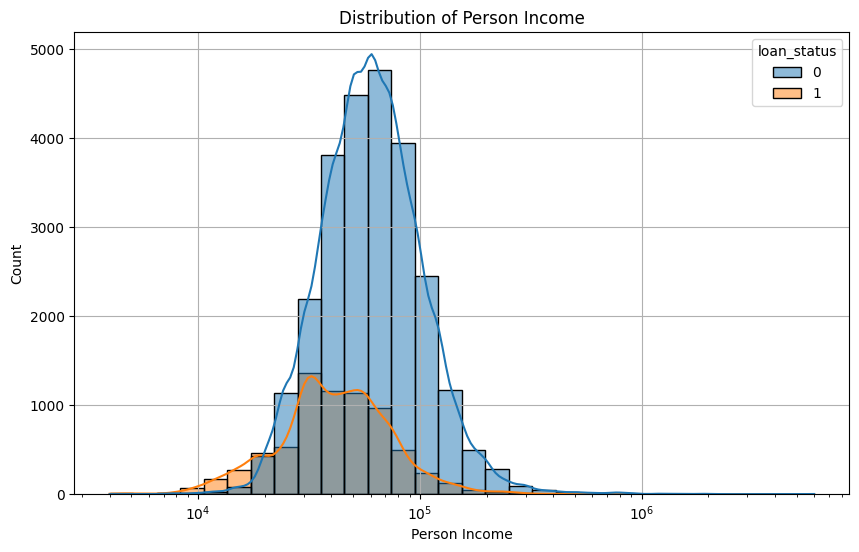

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(data=credit, x='person_income', hue='loan_status', bins=30, kde=True, ax=ax, log_scale=True)
ax.set_title('Distribution of Person Income')
ax.set_xlabel('Person Income')
ax.set_ylabel('Count')
ax.grid(True)
plt.show()


### Exercise 2(d) (5 points)

Create a side-by-side boxplot of `loan_int_rate` based on `loan_grade`. Describe the chart.

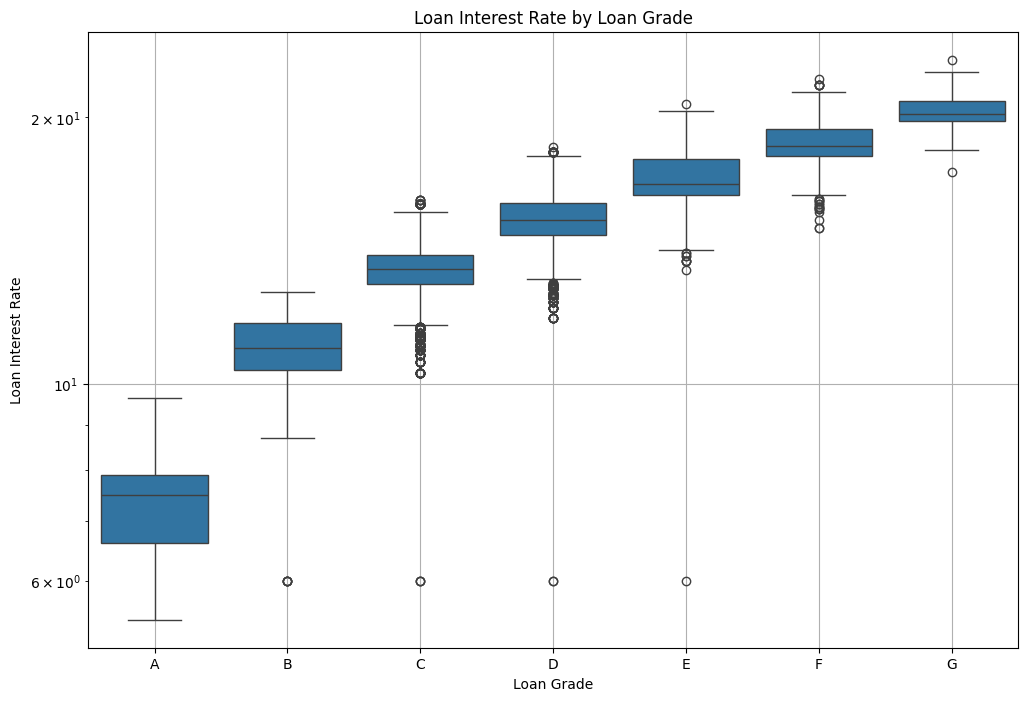

In [9]:
fig, ax = plt.subplots(figsize=(12, 8))

sns.boxplot(data=credit, x='loan_grade', y='loan_int_rate', ax=ax, log_scale=True, order=["A", "B", "C", "D", "E", "F", "G"])
ax.set_title('Loan Interest Rate by Loan Grade')
ax.set_xlabel('Loan Grade')
ax.set_ylabel('Loan Interest Rate')
ax.grid(True)
plt.show()

From the above chart, we see the interest rate is increasing from loan grade A to G.

### Exercise 2(e) (10 points)

Is there a realtionship between `person_home_ownership`, `loan_intent`, and `loan_status`? Create a heatmap that shows the average `loan_status` based on `person_home_ownership` and `loan_intent`. Describe the chart.

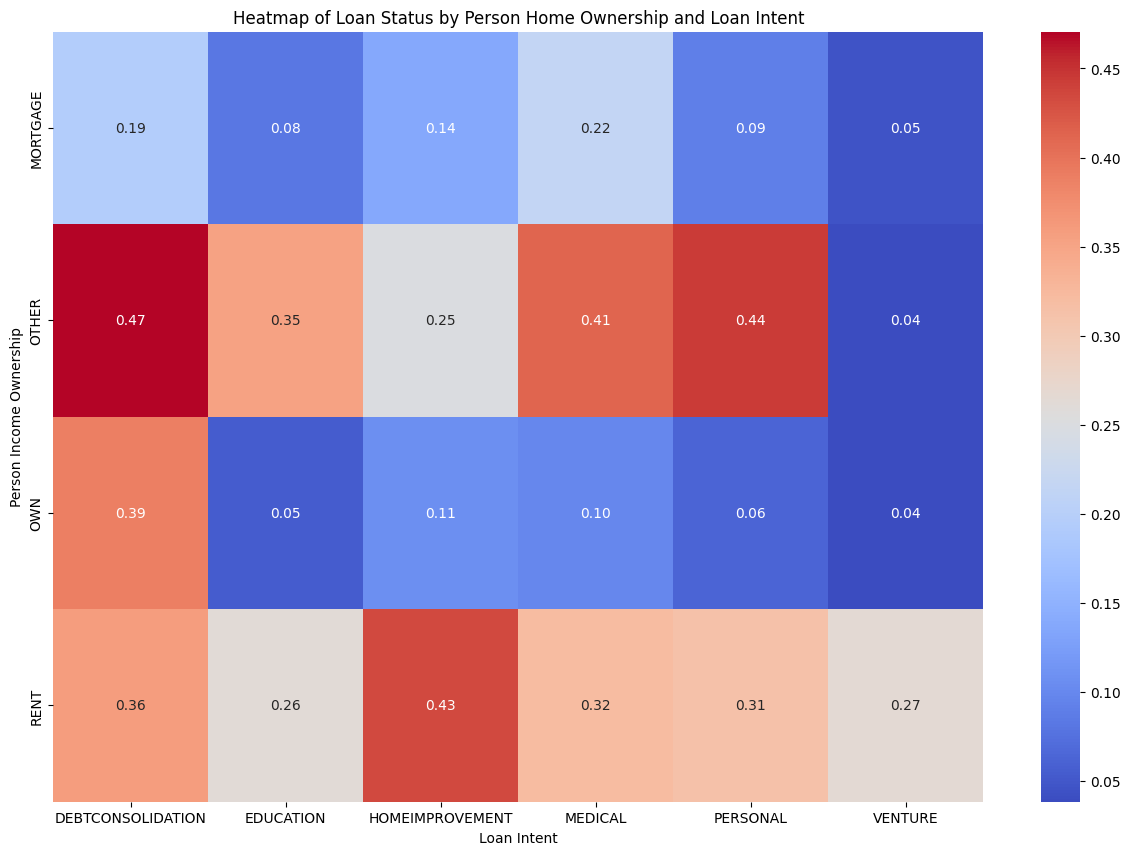

In [12]:
fig, ax = plt.subplots(figsize=(15, 10))

# Defining the categorical features
cat_features_1 = "person_home_ownership"
cat_features_2 = "loan_intent"
score = "loan_status"

# Creating the pivot table
pivot_table = credit.pivot_table(
    index=cat_features_1,
    columns=cat_features_2,
    values=score,
    aggfunc='mean'
)

# Plot the heatmap
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title('Heatmap of Loan Status by Person Home Ownership and Loan Intent')
ax.set_xlabel('Loan Intent')
ax.set_ylabel('Person Income Ownership')
plt.show()

From the above chart, these are a couple of observations:

- When person_home_ownership=OTHER, the likelihood of defaulting is higher.
- When person_home_ownership=RENT, the likelihood of defaulting is the second highest.

# Exercise 3 (10 points)

In this exercise, we will practice import formatting (Section 6.2 of Chapter 6).

### Exercise 3(a) (5 points)

The import block below grew organically and does not follow PEP8. Rewrite it so that:

- imports are grouped as (1) standard library, (2) third-party libraries, with a blank line between groups,
- imports are sorted alphabetically within each group (`import x` statements before `from x import y` statements),
- there is only one import per module line (for example, `import sys, os` must be split), and
- repeated imports from the same module are merged into a single line.


In [13]:
import time
from sklearn.metrics import accuracy_score

import sys, os
import numpy as np
from sklearn.model_selection import train_test_split
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, f1_score

In [ ]:
import time
from sklearn.metrics import accuracy_score

import sys, os
import numpy as np
from sklearn.model_selection import train_test_split
import pandas as pd

from sklearn.ensemble import HistGradientBoostingClassifier
import matplotlib.pyplot as plt

from sklearn.metrics import roc_auc_score, f1_score

In [15]:
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score
from sklearn.model_selection import train_test_split


### Exercise 3(b) (5 points)

Name two cases where reordering imports (for example, with `isort`) is **not** behavior-preserving. How can you tell `isort` to leave a line alone?

Two cases where reordering imports changes behavior:

• Order-dependent imports. Setting the matplotlib backend requires matplotlib.use("Agg") to run before matplotlib.pyplot is imported, sorting alphabetically can move it after.

• Registration (side-effect) imports. Some libraries are imported only for the side effect (e.g., registering a plugin or an accessor). A linter may flag them as unused and offer to delete them.

To make isort skip a line, add # isort: skip to that line (or wrap the block in # isort: off / # isort: on)